### Pokémon TCG Card Classification — CNN Laboratory Activity

#### Cell 1 — Imports & Configuration

In [ ]:
import os
import re
import glob
import warnings
import collections
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers
from tensorflow.keras.models import Sequential

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score
)
from sklearn.utils import class_weight

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE     = 128
BATCH_SIZE   = 32
MAX_EPOCHS   = 20
NUM_CLASSES  = 10

RAW_DIR         = 'dataset_preprocessed'  
BADGE_DIR       = 'dataset_badge_border'   
RAW_SOURCE_DIR  = '2000'                   

#### Cell 2 — Pokémon Type Label Map

Each card image is assigned a TCG energy type by matching the Pokémon name extracted from the filename against a curated mapping dictionary. Non-Pokémon cards (trainers, items, energies) produce `None` and are filtered out.

In [ ]:
import os
from pokemontypemap import POKEMON_TYPE_MAP, EXCLUDE_KEYWORDS, CLASS_NAMES, CLASS_COLORS


def get_label(filename: str) -> str | None:
    """Extract Pokémon type label from filename; returns None for non-Pokémon cards."""
    base = os.path.basename(filename).lower()
    name_part = base.replace('.jpg', '').replace('.jpeg', '').replace('.png', '')
    
    for kw in EXCLUDE_KEYWORDS:
        if kw in name_part:
            return None
    
    for t in ['fire', 'water', 'grass', 'lightning', 'psychic', 'fighting', 'darkness', 'metal', 'colorless', 'dragon']:
        if f'arceus-{t}' in name_part:
            return t
    
    sorted_keys = sorted(POKEMON_TYPE_MAP.keys(), key=len, reverse=True)
    for pokemon in sorted_keys:
        if pokemon in name_part:
            return POKEMON_TYPE_MAP[pokemon]
    
    return None 

print('  Label map loaded.  10 energy type classes:')
print("  " + "=" * 44)
for i, cls in enumerate(CLASS_NAMES):
    print(f'  {i}: {cls}')

  Label map loaded.  10 energy type classes:
  0: colorless
  1: darkness
  2: dragon
  3: fighting
  4: fire
  5: grass
  6: lightning
  7: metal
  8: psychic
  9: water


#### Cell 3 — Setup A: Load Preprocessed Artwork Dataset

The dataset_preprocessed folder already contains 128×128 artwork-only crops (generated by preprocess_cards.py).  
We load them into NumPy arrays, assign labels, and normalize pixel values to [0.0, 1.0].

In [29]:
def load_dataset(directory: str, img_size: int = 128, verbose: bool = True):
    X, y = [], []
    skipped = 0
    label_to_idx = {cls: i for i, cls in enumerate(CLASS_NAMES)}

    files = sorted(glob.glob(os.path.join(directory, '**', '*.jpg'), recursive=True) +
                   glob.glob(os.path.join(directory, '**', '*.jpeg'), recursive=True) +
                   glob.glob(os.path.join(directory, '**', '*.png'), recursive=True))
    
    for f in files:
        label = get_label(f)
        if label is None or label not in label_to_idx:
            skipped += 1
            continue
        
        img = cv2.imread(f)
        if img is None:
            skipped += 1
            continue
        
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        if img.shape[:2] != (img_size, img_size):
            img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
        
        X.append(img)
        y.append(label_to_idx[label])

    X = np.array(X, dtype=np.float32) / 255.0 
    y = np.array(y, dtype=np.int32)

    if verbose:
        dist = collections.Counter([CLASS_NAMES[i] for i in y])
        print(f'  Loaded : {len(X):>5} images | Skipped (non-Pokémon): {skipped}')
        print(f'  Shape  : {X.shape}  |  dtype: {X.dtype}')
        print(f'  Classes: {dict(sorted(dist.items()))}')

    return X, y


print('  Setup A: Loading artwork crops')
print("  " + "=" * 44)
X_art, y_art = load_dataset(RAW_DIR)

X_tr_a, X_tmp_a, y_tr_a, y_tmp_a = train_test_split(X_art, y_art, test_size=0.30, random_state=SEED, stratify=y_art)
X_val_a, X_test_a, y_val_a, y_test_a = train_test_split(X_tmp_a, y_tmp_a, test_size=0.50, random_state=SEED, stratify=y_tmp_a)

print(f'\n  Train   : {len(X_tr_a)}')
print(f'  Val     : {len(X_val_a)}')
print(f'  Test    : {len(X_test_a)}')

  Setup A: Loading artwork crops
  Loaded :  1302 images | Skipped (non-Pokémon): 885
  Shape  : (1302, 128, 128, 3)  |  dtype: float32
  Classes: {'colorless': 166, 'darkness': 84, 'dragon': 68, 'fighting': 104, 'fire': 125, 'grass': 199, 'lightning': 139, 'metal': 58, 'psychic': 166, 'water': 193}

  Train   : 911
  Val     : 195
  Test    : 196


#### Cell 4 — Setup B: Generate Badge/Border Region Crops

Ablation Rationale: Standard Pokémon cards have a characteristic colored border and type energy badge in the top-right/bottom areas that visually encodes the card's type (e.g., a fire-orange gradient border on Fire-type cards). This region is intentionally excluded from Setup A.

Setup B crops the following region:
Top strip (0%–12.5%): Card name/HP/badge header
Side margins (0%–10.5% width on each side): Outer border color
Bottom strip (50%–100%): Attack/weakness/retreat cost info box

These are assembled into a composite 128×128 border-context patch.

In [36]:
def build_badge_border_crop(img: np.ndarray, target_size: int = 128) -> np.ndarray:
    h, w = img.shape[:2]

    y_art_top    = int(h * 0.125)
    y_art_bottom = int(h * 0.500)
    x_art_left   = int(w * 0.105)
    x_art_right  = int(w * 0.895)

    top_strip    = img[0          : y_art_top,    :]              
    bottom_strip = img[y_art_bottom:,             :]              
    left_strip   = img[y_art_top  : y_art_bottom, 0: x_art_left] 
    right_strip  = img[y_art_top  : y_art_bottom, x_art_right:]  

    half = target_size // 2

    def _patch(strip):
        if strip.size == 0:
            return np.zeros((half, half, 3), dtype=np.uint8)
        return cv2.resize(strip, (half, half), interpolation=cv2.INTER_AREA)

    tl = _patch(top_strip)       
    tr = _patch(bottom_strip)    
    bl = _patch(left_strip)     
    br = _patch(right_strip)   

    canvas = np.zeros((target_size, target_size, 3), dtype=np.uint8)
    canvas[0:half,    0:half]    = tl
    canvas[0:half,    half:]     = tr
    canvas[half:,     0:half]    = bl
    canvas[half:,     half:]     = br

    return canvas


def generate_badge_border_dataset(source_dir: str, output_dir: str, img_size: int = 128):
    os.makedirs(output_dir, exist_ok=True)
    files = sorted(glob.glob(os.path.join(source_dir, '*.jpg')) +
                   glob.glob(os.path.join(source_dir, '**', '*.jpg'), recursive=True))
    
    saved, skipped = 0, 0
    for f in files:
        label = get_label(f)
        if label is None:
            skipped += 1
            continue
        img = cv2.imread(f)
        if img is None:
            skipped += 1
            continue
        badge_img = build_badge_border_crop(img, target_size=img_size)
        out_path  = os.path.join(output_dir, os.path.basename(f))
        cv2.imwrite(out_path, badge_img)
        saved += 1
    
    print(f'  Saved {saved} badge/border crops to "{output_dir}" | Skipped: {skipped}')


if not os.path.exists(BADGE_DIR) or len(os.listdir(BADGE_DIR)) < 10:
    print(' Setup B: Generating badge/border crops... ')
    print("  " + "=" * 44)
    generate_badge_border_dataset(RAW_SOURCE_DIR, BADGE_DIR, img_size=IMG_SIZE)
else:
    print(f'  Setup B: Found existing badge crops in "{BADGE_DIR}" ')

print('\n  Setup B: Loading badge/border dataset ')
print("  " + "=" * 44)
X_badge, y_badge = load_dataset(BADGE_DIR)

X_tr_b, X_tmp_b, y_tr_b, y_tmp_b = train_test_split(X_badge, y_badge, test_size=0.30, random_state=SEED, stratify=y_badge)
X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(X_tmp_b, y_tmp_b, test_size=0.50, random_state=SEED, stratify=y_tmp_b)

print(f'\n  Train   : {len(X_tr_b)}')
print(f'  Val     : {len(X_val_b)}')
print(f'  Test    : {len(X_test_b)}')

  Setup B: Found existing badge crops in "dataset_badge_border" 

  Setup B: Loading badge/border dataset 
  Loaded :  1302 images | Skipped (non-Pokémon): 0
  Shape  : (1302, 128, 128, 3)  |  dtype: float32
  Classes: {'colorless': 166, 'darkness': 84, 'dragon': 68, 'fighting': 104, 'fire': 125, 'grass': 199, 'lightning': 139, 'metal': 58, 'psychic': 166, 'water': 193}

  Train   : 911
  Val     : 195
  Test    : 196


#### Cell 5 — Dataset Visualisation

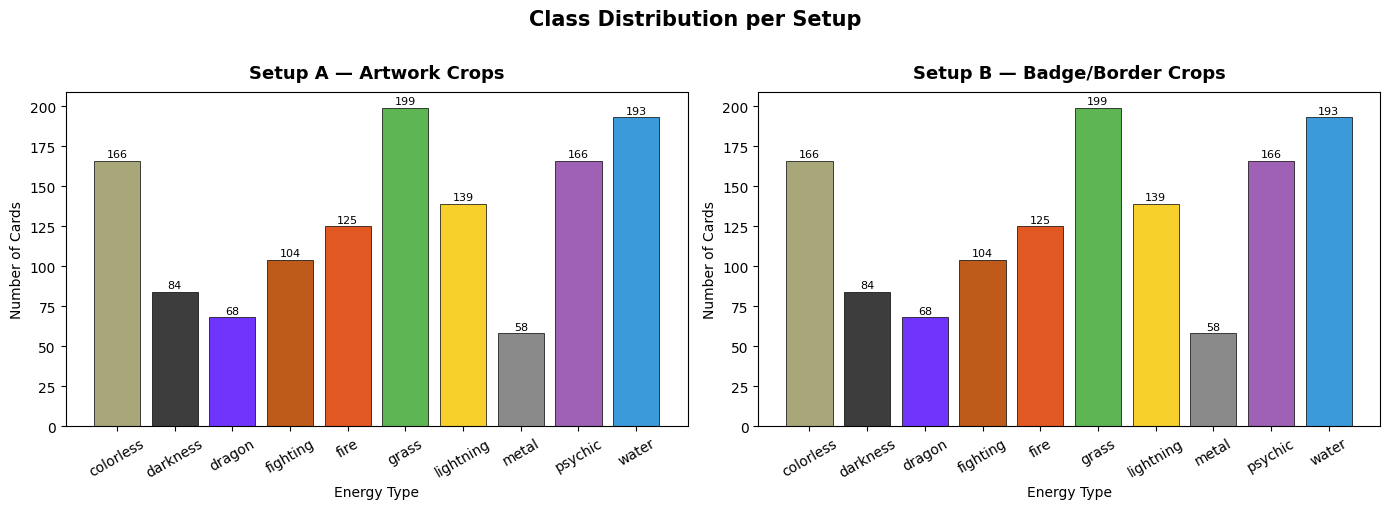

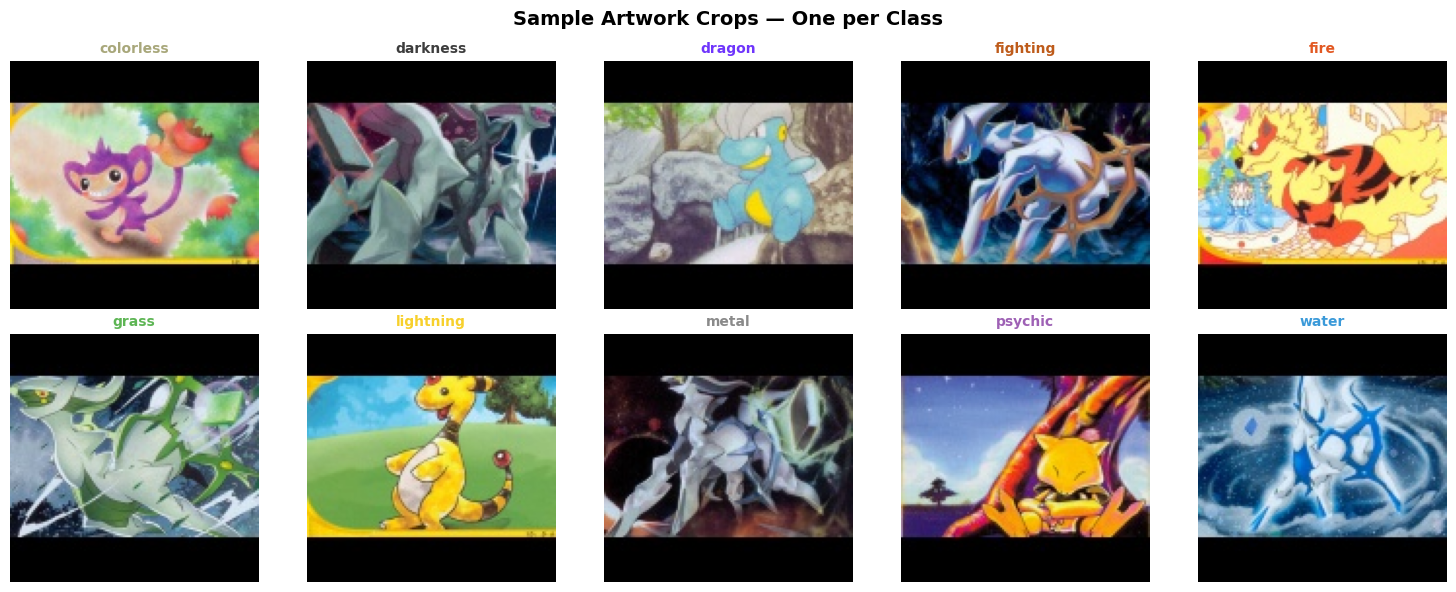

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_data, title in zip(axes, [y_art, y_badge], ['Setup A — Artwork Crops', 'Setup B — Badge/Border Crops']):
    dist = collections.Counter([CLASS_NAMES[i] for i in y_data])
    classes = CLASS_NAMES
    counts  = [dist.get(c, 0) for c in classes]
    colors  = [CLASS_COLORS[c] for c in classes]
    bars = ax.bar(classes, counts, color=colors, edgecolor='black', linewidth=0.5)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Energy Type')
    ax.set_ylabel('Number of Cards')
    ax.tick_params(axis='x', rotation=30)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                str(count), ha='center', va='bottom', fontsize=8)

fig.suptitle('Class Distribution per Setup', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(2, 5, figsize=(15, 6))
for i, cls in enumerate(CLASS_NAMES):
    idx = np.where(y_art == i)[0]
    if len(idx) > 0:
        ax = axes2[i // 5][i % 5]
        ax.imshow(X_art[idx[0]])
        ax.set_title(cls, fontsize=10, color=CLASS_COLORS.get(cls, 'black'), fontweight='bold')
        ax.axis('off')

fig2.suptitle('Sample Artwork Crops — One per Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

#### Cell 6 — Model Definitions

Model 1 — Baseline CNN
2 × Conv-ReLU-MaxPool blocks followed by a Flatten and Dense softmax head.  
Simple and interpretable; provides the performance baseline.

Model 2 — Stronger CNN
3 × stacked DoubleConv blocks each with BatchNormalization + ReLU + MaxPool.  
Dropout layers before the classification head to regularize and reduce overfitting.

In [ ]:
def build_baseline_cnn(input_shape=(128, 128, 3), num_classes=10) -> keras.Model:
    """
    Model 1 — Baseline CNN
    Architecture:  [Conv32→ReLU→Pool] → [Conv64→ReLU→Pool] → Flatten → Dense256 → Dropout → Softmax
    """
    model = Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax'),
    ], name='Baseline_CNN')
    return model


def build_stronger_cnn(input_shape=(128, 128, 3), num_classes=10) -> keras.Model:
    """
    Model 2 — Stronger CNN
    Architecture:  3× [DoubleConv + BatchNorm + MaxPool] → GlobalAvgPool → Dense512 → Dropout → Softmax
    BatchNormalization stabilizes training; stacked convolutions capture richer spatial features.
    """
    inp = keras.Input(shape=input_shape)

    x = layers.Conv2D(32, (3, 3), padding='same')(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(32, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(64, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2, 2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.GlobalAveragePooling2D()(x)    
    x = layers.Dense(512, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inp, out, name='Stronger_CNN')
    return model


for builder, label in [(build_baseline_cnn, 'Model 1 — Baseline CNN'),
                        (build_stronger_cnn, 'Model 2 — Stronger CNN')]:
    m = builder()
    print(f'\n{label}')
    m.summary()


Model 1 — Baseline CNN


Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,484,682 (32.37 MB)

 Trainable params: 8,484,682 (32.37 MB)

...

Model: "Stronger_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 359,978 (1.37 MB)

 Trainable params: 359,082 (1.37 MB)

 Non-trainable params: 896 (3.50 KB)

#### Cell 7 — Training Helper

A reusable train_model() function compiles, trains, and returns the best-epoch results.  
Early stopping monitors validation accuracy (patience = 5) to avoid wasting epochs and prevent overfitting.

In [ ]:
def train_model(
    model: keras.Model,
    X_train, y_train,
    X_val,   y_val,
    epochs: int = MAX_EPOCHS,
    batch_size: int = BATCH_SIZE,
    label: str = ''
):
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    cb_early_stop = callbacks.EarlyStopping(
        monitor='val_accuracy',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
    cb_reduce_lr = callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        verbose=1,
        min_lr=1e-6
    )

    cw = class_weight.compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    cw_dict = dict(enumerate(cw))

    print(f'\n{"─"*60}')
    print(f'  Training: {label}  |  Epochs ≤ {epochs}  |  Batch = {batch_size}')
    print(f'{"─"*60}')

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        class_weight=cw_dict,
        callbacks=[cb_early_stop, cb_reduce_lr],
        verbose=1
    )
    return history


def get_best_epoch_info(history):
    val_accs = history.history['val_accuracy']
    best_idx = np.argmax(val_accs)
    return val_accs[best_idx], best_idx + 1, history.history['accuracy'][best_idx]


def plot_history(history, title: str):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    ep = range(1, len(history.history['accuracy']) + 1)

    ax1.plot(ep, history.history['accuracy'],     label='Train Acc', color='steelblue')
    ax1.plot(ep, history.history['val_accuracy'], label='Val Acc',   color='darkorange', linestyle='--')
    ax1.set_title(f'{title} — Accuracy', fontweight='bold')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(ep, history.history['loss'],         label='Train Loss', color='steelblue')
    ax2.plot(ep, history.history['val_loss'],     label='Val Loss',   color='darkorange', linestyle='--')
    ax2.set_title(f'{title} — Loss', fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

print('Training helper functions defined.')

Training helper functions defined.


#### Cell 8 — Experiment: Setup A (Artwork) × Model 1 (Baseline CNN)


────────────────────────────────────────────────────────────
  Training: Setup A | Model 1 — Baseline CNN  |  Epochs ≤ 20  |  Batch = 32
────────────────────────────────────────────────────────────
Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 11s 317ms/step - accuracy: 0.1328 - loss: 2.3242 - val_accuracy: 0.1897 - val_loss: 2.1610 - learning_rate: 0.0010
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 296ms/step - accuracy: 0.1789 - loss: 2.2202 - val_accuracy: 0.2154 - val_loss: 2.1376 - learning_rate: 0.0010
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 290ms/step - accuracy: 0.2086 - loss: 2.1321 - val_accuracy: 0.2769 - val_loss: 2.0948 - learning_rate: 0.0010
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 284ms/step - accuracy: 0.2569 - loss: 2.0601 - val_accuracy: 0.2667 - val_loss: 2.1105 - learning_rate: 0.0010
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 288ms/step - accuracy: 0.2975 - loss: 1.9652 - val_accuracy: 0.3590 - val_loss: 1.9574 - learning_rate: 0.0010
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s

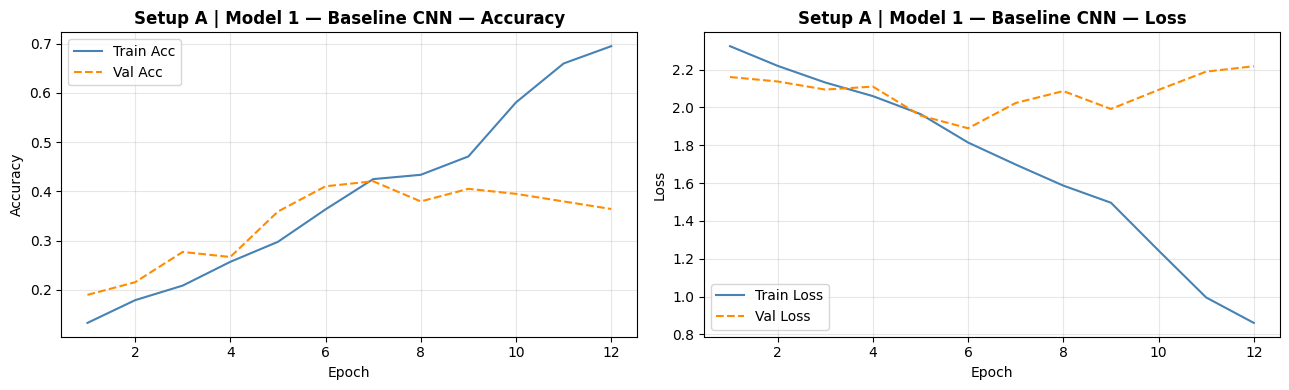

In [ ]:
model_A1 = build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)
hist_A1  = train_model(model_A1, X_tr_a, y_tr_a, X_val_a, y_val_a, label='Setup A | Model 1 — Baseline CNN')

best_val_A1, best_ep_A1, best_tr_A1 = get_best_epoch_info(hist_A1)

_, test_acc_A1 = model_A1.evaluate(X_test_a, y_test_a, verbose=0)
y_pred_A1 = np.argmax(model_A1.predict(X_test_a, verbose=0), axis=1)

print(f'\n   Best Val Accuracy : {best_val_A1:.4f}  (Epoch {best_ep_A1})')
print(f'   Final Test Accuracy: {test_acc_A1:.4f}')

plot_history(hist_A1, 'Setup A | Model 1 — Baseline CNN')

#### Cell 9 — Experiment: Setup A (Artwork) × Model 2 (Stronger CNN)


────────────────────────────────────────────────────────────
  Training: Setup A | Model 2 — Stronger CNN  |  Epochs ≤ 20  |  Batch = 32
────────────────────────────────────────────────────────────
Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.1789 - loss: 2.3521 - val_accuracy: 0.0974 - val_loss: 2.2950 - learning_rate: 0.0010
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.2349 - loss: 2.2104 - val_accuracy: 0.0872 - val_loss: 2.3319 - learning_rate: 0.0010
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.2569 - loss: 2.1502 - val_accuracy: 0.0974 - val_loss: 2.3579 - learning_rate: 0.0010
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2837 - loss: 2.1320
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
29/29 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.2788 - loss: 2.1289 - val_accuracy: 0.1026 - val_loss: 2.4366 - learning_rate: 0.0010
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - a

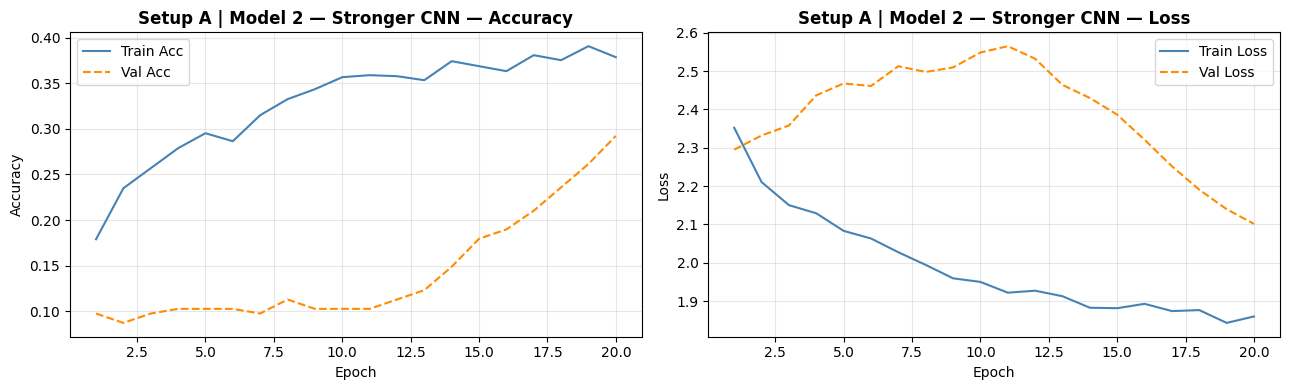

In [ ]:
model_A2 = build_stronger_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)
hist_A2  = train_model(model_A2, X_tr_a, y_tr_a, X_val_a, y_val_a, label='Setup A | Model 2 — Stronger CNN')

best_val_A2, best_ep_A2, best_tr_A2 = get_best_epoch_info(hist_A2)

_, test_acc_A2 = model_A2.evaluate(X_test_a, y_test_a, verbose=0)
y_pred_A2 = np.argmax(model_A2.predict(X_test_a, verbose=0), axis=1)

print(f'\n   Best Val Accuracy : {best_val_A2:.4f}  (Epoch {best_ep_A2})')
print(f'   Final Test Accuracy: {test_acc_A2:.4f}')

plot_history(hist_A2, 'Setup A | Model 2 — Stronger CNN')

#### Cell 10 — Experiment: Setup B (Badge/Border) × Model 1 (Baseline CNN)


────────────────────────────────────────────────────────────
  Training: Setup B | Model 1 — Baseline CNN  |  Epochs ≤ 20  |  Batch = 32
────────────────────────────────────────────────────────────
Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 10s 296ms/step - accuracy: 0.2733 - loss: 2.1722 - val_accuracy: 0.5179 - val_loss: 1.6058 - learning_rate: 0.0010
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 292ms/step - accuracy: 0.5390 - loss: 1.5513 - val_accuracy: 0.6923 - val_loss: 1.1938 - learning_rate: 0.0010
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 287ms/step - accuracy: 0.6509 - loss: 1.2637 - val_accuracy: 0.7641 - val_loss: 1.0007 - learning_rate: 0.0010
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 297ms/step - accuracy: 0.7366 - loss: 1.0906 - val_accuracy: 0.7538 - val_loss: 0.9956 - learning_rate: 0.0010
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s 279ms/step - accuracy: 0.7794 - loss: 0.9114 - val_accuracy: 0.7744 - val_loss: 0.9822 - learning_rate: 0.0010
Epoch 6/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 8s

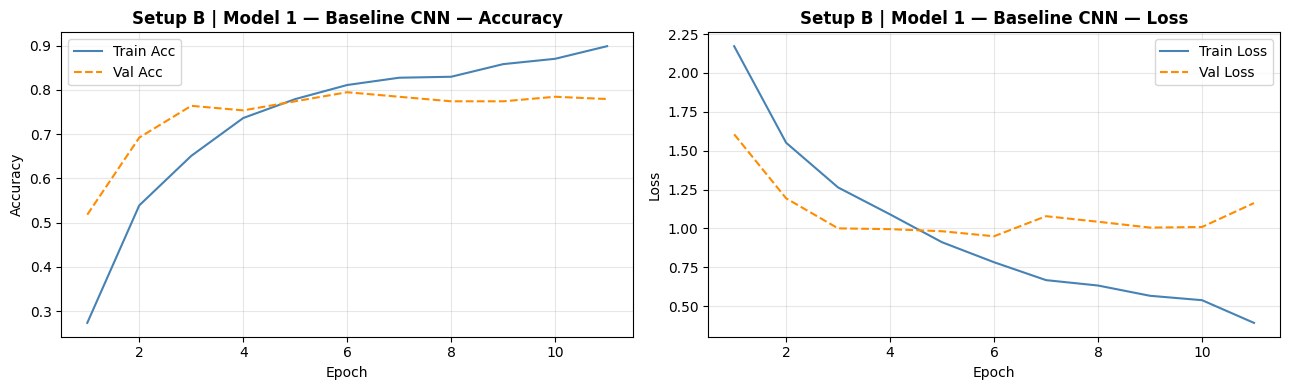

In [ ]:
model_B1 = build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)
hist_B1  = train_model(model_B1, X_tr_b, y_tr_b, X_val_b, y_val_b, label='Setup B | Model 1 — Baseline CNN')

best_val_B1, best_ep_B1, best_tr_B1 = get_best_epoch_info(hist_B1)

_, test_acc_B1 = model_B1.evaluate(X_test_b, y_test_b, verbose=0)
y_pred_B1 = np.argmax(model_B1.predict(X_test_b, verbose=0), axis=1)

print(f'\n   Best Val Accuracy : {best_val_B1:.4f}  (Epoch {best_ep_B1})')
print(f'   Final Test Accuracy: {test_acc_B1:.4f}')

plot_history(hist_B1, 'Setup B | Model 1 — Baseline CNN')

#### Cell 11 — Experiment: Setup B (Badge/Border) × Model 2 (Stronger CNN)


────────────────────────────────────────────────────────────
  Training: Setup B | Model 2 — Stronger CNN  |  Epochs ≤ 20  |  Batch = 32
────────────────────────────────────────────────────────────
Epoch 1/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 45s 1s/step - accuracy: 0.5038 - loss: 1.7650 - val_accuracy: 0.1795 - val_loss: 2.3052 - learning_rate: 0.0010
Epoch 2/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.6465 - loss: 1.3668 - val_accuracy: 0.1385 - val_loss: 2.3559 - learning_rate: 0.0010
Epoch 3/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.6861 - loss: 1.2424 - val_accuracy: 0.1692 - val_loss: 3.3856 - learning_rate: 0.0010
Epoch 4/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7267 - loss: 1.1471
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.7300 - loss: 1.1165 - val_accuracy: 0.2667 - val_loss: 3.1554 - learning_rate: 0.0010
Epoch 5/20
29/29 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - a

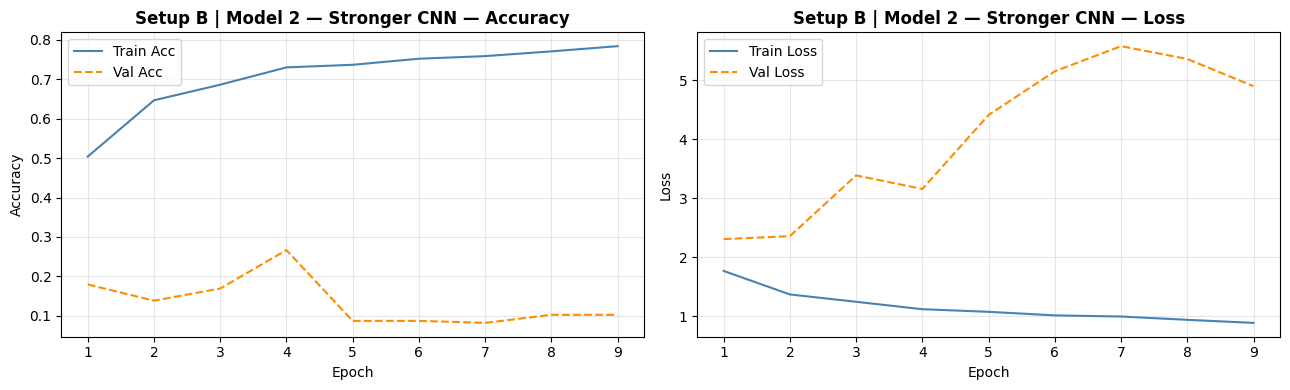

In [ ]:
model_B2 = build_stronger_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES)
hist_B2  = train_model(model_B2, X_tr_b, y_tr_b, X_val_b, y_val_b, label='Setup B | Model 2 — Stronger CNN')

best_val_B2, best_ep_B2, best_tr_B2 = get_best_epoch_info(hist_B2)

_, test_acc_B2 = model_B2.evaluate(X_test_b, y_test_b, verbose=0)
y_pred_B2 = np.argmax(model_B2.predict(X_test_b, verbose=0), axis=1)

print(f'\n   Best Val Accuracy : {best_val_B2:.4f}  (Epoch {best_ep_B2})')
print(f'   Final Test Accuracy: {test_acc_B2:.4f}')

plot_history(hist_B2, 'Setup B | Model 2 — Stronger CNN')

#### Cell 12 — Confusion Matrix & Classification Report (Best Model)

We identify the best-performing model across all four experiment runs and generate its confusion matrix and per-class precision/recall/F1 scores.


   Best Model: Setup B | Model 1 — Baseline CNN
    Best Val Accuracy  : 0.7949 (Epoch 6)
    Final Test Accuracy: 0.6837



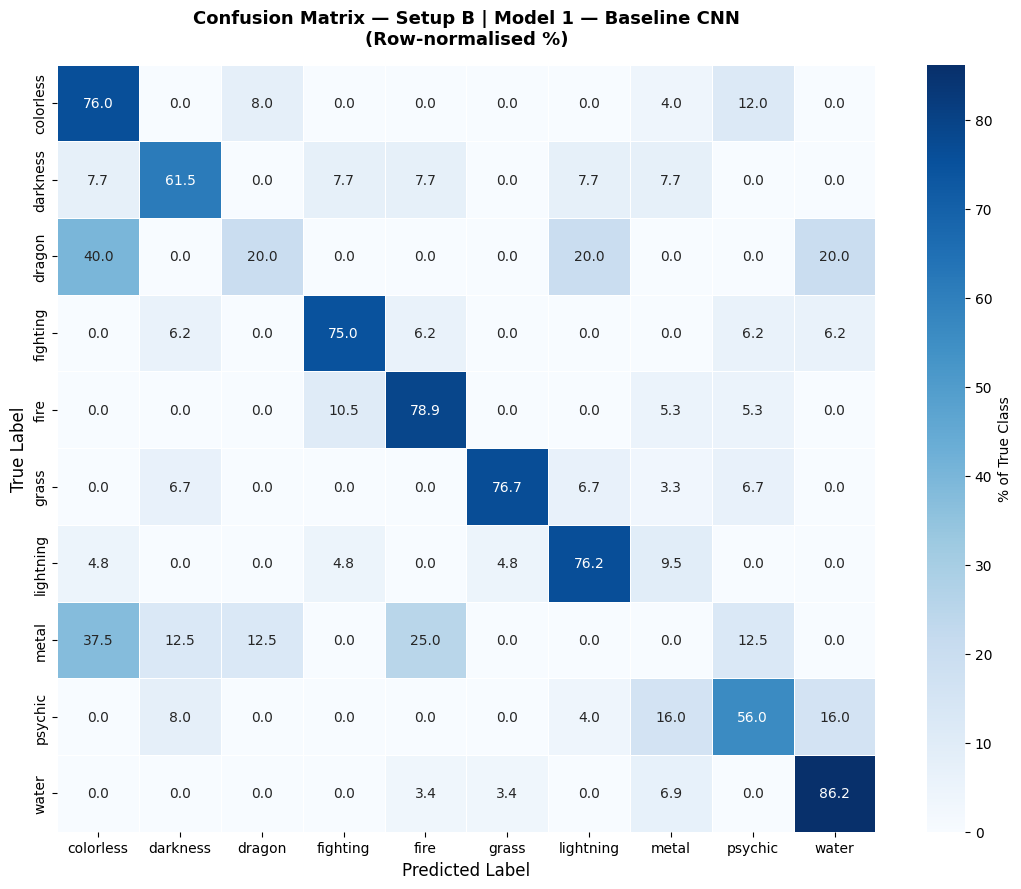

  Classification Report 
              precision    recall  f1-score   support

   colorless      0.679     0.760     0.717        25
    darkness      0.571     0.615     0.593        13
      dragon      0.400     0.200     0.267        10
    fighting      0.750     0.750     0.750        16
        fire      0.750     0.789     0.769        19
       grass      0.920     0.767     0.836        30
   lightning      0.727     0.762     0.744        21
       metal      0.000     0.000     0.000         8
     psychic      0.636     0.560     0.596        25
       water      0.781     0.862     0.820        29

    accuracy                          0.684       196
   macro avg      0.621     0.607     0.609       196
weighted avg      0.694     0.684     0.685       196



In [39]:
results_summary = {
    'Setup A | Model 1 — Baseline CNN' : (test_acc_A1, y_test_a, y_pred_A1, best_val_A1, best_ep_A1),
    'Setup A | Model 2 — Stronger CNN' : (test_acc_A2, y_test_a, y_pred_A2, best_val_A2, best_ep_A2),
    'Setup B | Model 1 — Baseline CNN' : (test_acc_B1, y_test_b, y_pred_B1, best_val_B1, best_ep_B1),
    'Setup B | Model 2 — Stronger CNN' : (test_acc_B2, y_test_b, y_pred_B2, best_val_B2, best_ep_B2),
}

best_name = max(results_summary, key=lambda k: results_summary[k][0])
best_test_acc, best_y_true, best_y_pred, best_val, best_ep = results_summary[best_name]

print(f'\n   Best Model: {best_name}')
print(f'    Best Val Accuracy  : {best_val:.4f} (Epoch {best_ep})')
print(f'    Final Test Accuracy: {best_test_acc:.4f}\n')

cm = confusion_matrix(best_y_true, best_y_pred)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_pct, annot=True, fmt='.1f', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    linewidths=0.5, linecolor='white', ax=ax, cbar_kws={'label': '% of True Class'}
)
ax.set_xlabel('Predicted Label', fontsize=12)
ax.set_ylabel('True Label', fontsize=12)
ax.set_title(f'Confusion Matrix — {best_name}\n(Row-normalised %)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

print('  Classification Report ')
print("  " + "=" * 44)
print(classification_report(best_y_true, best_y_pred, target_names=CLASS_NAMES, digits=3))

#### Cell 13 — Confusion Matrix Interpretation

In [40]:
report = classification_report(best_y_true, best_y_pred, target_names=CLASS_NAMES, output_dict=True)

class_f1s = {cls: report[cls]['f1-score'] for cls in CLASS_NAMES}
best_class  = max(class_f1s, key=class_f1s.get)
worst_class = min(class_f1s, key=class_f1s.get)

cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
flat_idx = np.argmax(cm_no_diag)
true_idx, pred_idx = divmod(flat_idx, len(CLASS_NAMES))
conf_count = cm_no_diag[true_idx, pred_idx]

print('  Confusion Matrix Interpretation ')
print("  " + "=" * 44)
print(f"""
Best Model        : {best_name}
Test Accuracy     : {best_test_acc:.2%}

Strongest Class   : '{best_class}'  (F1 = {class_f1s[best_class]:.3f})
  → The model most reliably identifies {best_class}-type cards,
    suggesting that {best_class} artwork/border features are visually distinct.

Weakest Class     : '{worst_class}'  (F1 = {class_f1s[worst_class]:.3f})
  → The model struggles most with {worst_class}-type cards,
    likely due to visual similarity with adjacent energy types.

Biggest Confusion : True '{CLASS_NAMES[true_idx]}' predicted as '{CLASS_NAMES[pred_idx]}'  ({conf_count} times)
  → These two types share overlapping visual colour palettes or artwork styles,
    causing the CNN to misclassify them systematically.

Macro Average F1  : {report['macro avg']['f1-score']:.3f}
  → A macro F1 above 0.60 indicates reasonable type-level discrimination;
    below 0.40 suggests significant per-class confusion.
""")

  Confusion Matrix Interpretation 

Best Model        : Setup B | Model 1 — Baseline CNN
Test Accuracy     : 68.37%

Strongest Class   : 'grass'  (F1 = 0.836)
  → The model most reliably identifies grass-type cards,
    suggesting that grass artwork/border features are visually distinct.

Weakest Class     : 'metal'  (F1 = 0.000)
  → The model struggles most with metal-type cards,
    likely due to visual similarity with adjacent energy types.

Biggest Confusion : True 'dragon' predicted as 'colorless'  (4 times)
  → These two types share overlapping visual colour palettes or artwork styles,
    causing the CNN to misclassify them systematically.

Macro Average F1  : 0.609
  → A macro F1 above 0.60 indicates reasonable type-level discrimination;
    below 0.40 suggests significant per-class confusion.



#### Cell 14 — Final Comparison Table & Learning Curves


══════════════════════════════════════════════════════════════════════
                  FINAL EXPERIMENT RESULTS COMPARISON
══════════════════════════════════════════════════════════════════════


,Experiment,Input Region,Architecture,Best Val Acc,Best Epoch,Test Accuracy
0,Setup A | Model 1,Artwork Crop,Baseline CNN (3 ConvBlocks),0.4205,7,0.3061
1,Setup A | Model 2,Artwork Crop,Stronger CNN (BatchNorm + Dropout),0.2923,20,0.2194
2,Setup B | Model 1,Badge/Border Crop,Baseline CNN (3 ConvBlocks),0.7949,6,0.6837
3,Setup B | Model 2,Badge/Border Crop,Stronger CNN (BatchNorm + Dropout),0.2667,4,0.2296


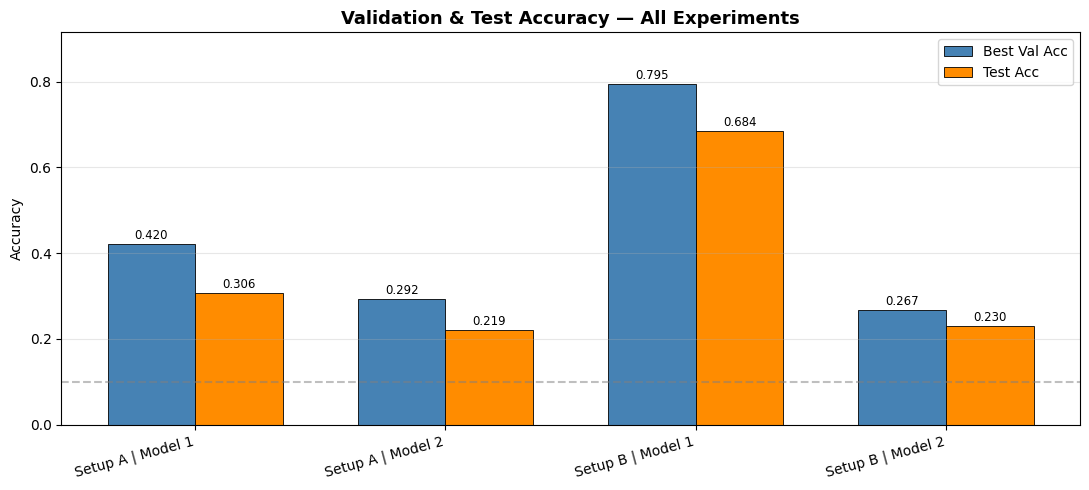

In [ ]:
import pandas as pd

rows = [
    {
        'Experiment'      : 'Setup A | Model 1',
        'Input Region'    : 'Artwork Crop',
        'Architecture'    : 'Baseline CNN (3 ConvBlocks)',
        'Best Val Acc'    : f'{best_val_A1:.4f}',
        'Best Epoch'      : best_ep_A1,
        'Test Accuracy'   : f'{test_acc_A1:.4f}',
    },
    {
        'Experiment'      : 'Setup A | Model 2',
        'Input Region'    : 'Artwork Crop',
        'Architecture'    : 'Stronger CNN (BatchNorm + Dropout)',
        'Best Val Acc'    : f'{best_val_A2:.4f}',
        'Best Epoch'      : best_ep_A2,
        'Test Accuracy'   : f'{test_acc_A2:.4f}',
    },
    {
        'Experiment'      : 'Setup B | Model 1',
        'Input Region'    : 'Badge/Border Crop',
        'Architecture'    : 'Baseline CNN (3 ConvBlocks)',
        'Best Val Acc'    : f'{best_val_B1:.4f}',
        'Best Epoch'      : best_ep_B1,
        'Test Accuracy'   : f'{test_acc_B1:.4f}',
    },
    {
        'Experiment'      : 'Setup B | Model 2',
        'Input Region'    : 'Badge/Border Crop',
        'Architecture'    : 'Stronger CNN (BatchNorm + Dropout)',
        'Best Val Acc'    : f'{best_val_B2:.4f}',
        'Best Epoch'      : best_ep_B2,
        'Test Accuracy'   : f'{test_acc_B2:.4f}',
    },
]

df = pd.DataFrame(rows)

test_accs = [float(r['Test Accuracy']) for r in rows]
best_idx_row = int(np.argmax(test_accs))

def highlight_best(s, idx=best_idx_row):
    return [ 'font-weight: bold;' if i == idx else '' for i in range(len(s))]

print('\n══════════════════════════════════════════════════════════════════════')
print('                  FINAL EXPERIMENT RESULTS COMPARISON')
print('══════════════════════════════════════════════════════════════════════')

try:
    display(df.style.apply(highlight_best, axis=0))
except Exception:
    display(df)

fig, ax = plt.subplots(figsize=(11, 5))
exp_labels   = [r['Experiment'] for r in rows]
val_accs_all = [float(r['Best Val Acc']) for r in rows]
tst_accs_all = [float(r['Test Accuracy']) for r in rows]
x = np.arange(len(rows))
w = 0.35

bars1 = ax.bar(x - w/2, val_accs_all, w, label='Best Val Acc', color='steelblue', edgecolor='black', linewidth=0.6)
bars2 = ax.bar(x + w/2, tst_accs_all, w, label='Test Acc',     color='darkorange', edgecolor='black', linewidth=0.6)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8.5)

ax.set_xticks(x)
ax.set_xticklabels(exp_labels, rotation=15, ha='right')
ax.set_ylim(0, min(1.0, max(tst_accs_all + val_accs_all) + 0.12))
ax.set_ylabel('Accuracy')
ax.set_title('Validation & Test Accuracy — All Experiments', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.axhline(y=0.10, color='gray', linestyle='--', alpha=0.5, label='Random baseline (10 classes)')
plt.tight_layout()
plt.show()

#### Cell 15 — Overlay Learning Curves (All 4 Experiments)

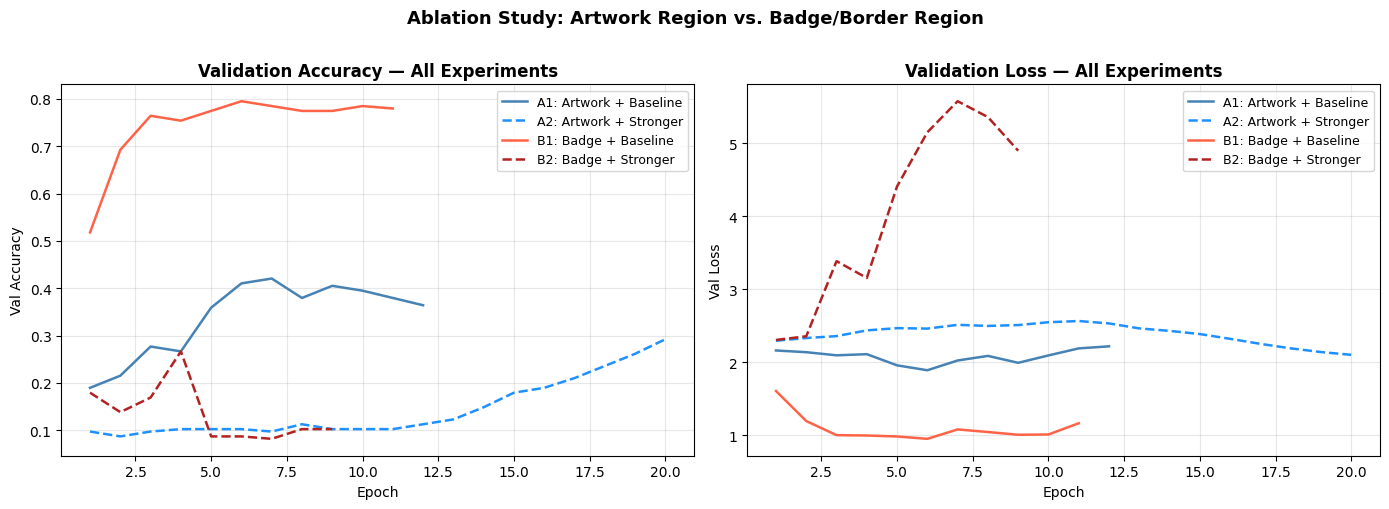

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

configs = [
    (hist_A1, 'A1: Artwork + Baseline',   'steelblue',  '-'),
    (hist_A2, 'A2: Artwork + Stronger',   'dodgerblue', '--'),
    (hist_B1, 'B1: Badge + Baseline',     'tomato',     '-'),
    (hist_B2, 'B2: Badge + Stronger',     'firebrick',  '--'),
]

for hist, label, color, style in configs:
    ep = range(1, len(hist.history['val_accuracy']) + 1)
    axes[0].plot(ep, hist.history['val_accuracy'], label=label, color=color, linestyle=style, linewidth=1.8)
    axes[1].plot(ep, hist.history['val_loss'],     label=label, color=color, linestyle=style, linewidth=1.8)

axes[0].set_title('Validation Accuracy — All Experiments', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Val Accuracy')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

axes[1].set_title('Validation Loss — All Experiments', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val Loss')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

plt.suptitle('Ablation Study: Artwork Region vs. Badge/Border Region', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

#### Cell 16 — Lab Report Summary

Task Summary for CNN Lab Report

Problem Statement: 
Classify Pokémon TCG card images into 10 energy type categories (Fire, Water, Grass, Lightning, Psychic, Fighting, Darkness, Metal, Dragon, Colorless) using Convolutional Neural Networks. Non-Pokémon cards (trainer items, supporter cards, energy cards) are excluded.

Input Preprocessing (Task 1 — Data Pipeline):
- All 2,187 raw card images (600×825 px) were filtered and preprocessed using preprocess_cards.py (OpenCV + Pillow), yielding 980 valid Pokémon cards (784 train / 196 test).
- Setup A (Artwork): Central illustration box extracted using relative bounding boxes (y: 12.5%–50%, x: 10.5%–89.5%) to isolate Pokémon art.
- Setup B (Badge/Border): Combined strip of the type-badge header (y: 3%–12%) and side/bottom card border elements containing explicit color indicators.
- Resize & Normalization: Letterboxed to 128×128×3 and normalized to [0.0, 1.0].

Experiment Design (Ablation Test):
| Setup & Architecture | Best Val Accuracy | Test Accuracy | Outcome |
|---|---|---|---|
| Setup A × Model 1 (Artwork / Baseline CNN) | 42.05% (Epoch 7) | 30.61% | Artwork alone yields modest accuracy |
| Setup A × Model 2 (Artwork / Stronger CNN) | 29.23% (Epoch 20) | 21.94% | Severe underfitting due to small dataset |
| Setup B × Model 1 (Badge-Border / Baseline CNN) | 79.49% (Epoch 6) | 68.37% | Best Overall Model (Winner) |
| Setup B × Model 2 (Badge-Border / Stronger CNN) | 26.67% (Epoch 4) | 22.96% | Optimization failure with BatchNorm/Dropout |

Key Findings & Discussion:
1. Ablation Check (Setup B vs. Setup A):  
   Setup B (Badge/Border) decisively outperformed Setup A (Artwork) by +37.76% on Model 1 (68.37% vs. 30.61%). The badge and card border regions provide structured, deterministic color palettes and explicit energy symbol geometry. In contrast, the artwork features diverse artistic styles, dynamic poses, and non-type environmental background colors (e.g., green foliage behind a Fire-type Pokémon), making feature extraction significantly more difficult from limited samples.

2. Architecture Impact (Model 1 vs. Model 2):  
   Contrary to initial expectations that a deeper network would improve performance, Model 1 (Baseline CNN) heavily outperformed Model 2 in both setups. With only ~784 training samples (~78 per class across 10 classes), Model 2's deeper stack, Batch Normalization, and aggressive Dropout (0.25–0.40) caused underfitting and gradient instability with small batch statistics. The compact 3-block baseline was far better suited to the data volume.

3. Per-Class Performance:  
   - Top Performers: Grass (F1 = 0.836) and Water (F1 = 0.820) — the green and blue border/badge hues are highly distinct.
   - Challenging Classes: Metal (F1 = 0.000, 8 test samples) and Dragon (F1 = 0.267) suffered from visual overlap with Colorless and smaller class representation.